### Amostragem

In [8]:
# Importando e lendo CSV

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10,5)

df = pd.read_csv('seoul_bike_tratado.csv')

print(df.shape)
df.head()

(8760, 15)


,date,rented_bike_count,hour,temperature(°c),humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature(°c),solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,timestamp
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 00:00:00
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 01:00:00
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 02:00:00
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 03:00:00
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 04:00:00


In [9]:
# Selecionando os registros que tiveram dias funcionais

df_func = df[df['functioning_day'] == 'Yes']
print(df_func.shape)
df_func.head()

(8465, 15)


,date,rented_bike_count,hour,temperature(°c),humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature(°c),solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,timestamp
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 00:00:00
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 01:00:00
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 02:00:00
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 03:00:00
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017-12-01 04:00:00


In [10]:
# Selecionando a amostra

amostra = (df_func.groupby('seasons').sample(frac=0.20, random_state=42))

print(amostra.shape)
amostra.head()

(1693, 15)


,date,rented_bike_count,hour,temperature(°c),humidity(%),wind_speed_(m/s),visibility_(10m),dew_point_temperature(°c),solar_radiation_(mj/m2),rainfall(mm),snowfall_(cm),seasons,holiday,functioning_day,timestamp
7206,2018-09-27,589,6,13.4,61,0.8,2000,6.0,0.00,0.0,0.0,Autumn,No Holiday,Yes,2018-09-27 06:00:00
7652,2018-10-15,1659,20,15.9,81,2.8,250,12.6,0.00,0.0,0.0,Autumn,No Holiday,Yes,2018-10-15 20:00:00
7658,2018-10-16,427,2,11.7,70,1.0,1012,6.4,0.00,0.0,0.0,Autumn,No Holiday,Yes,2018-10-16 02:00:00
8577,2018-11-23,800,9,-1.5,33,0.9,1962,-15.7,0.57,0.0,0.0,Autumn,No Holiday,Yes,2018-11-23 09:00:00
8287,2018-11-11,228,7,6.4,84,1.3,369,3.8,0.00,0.0,0.0,Autumn,No Holiday,Yes,2018-11-11 07:00:00


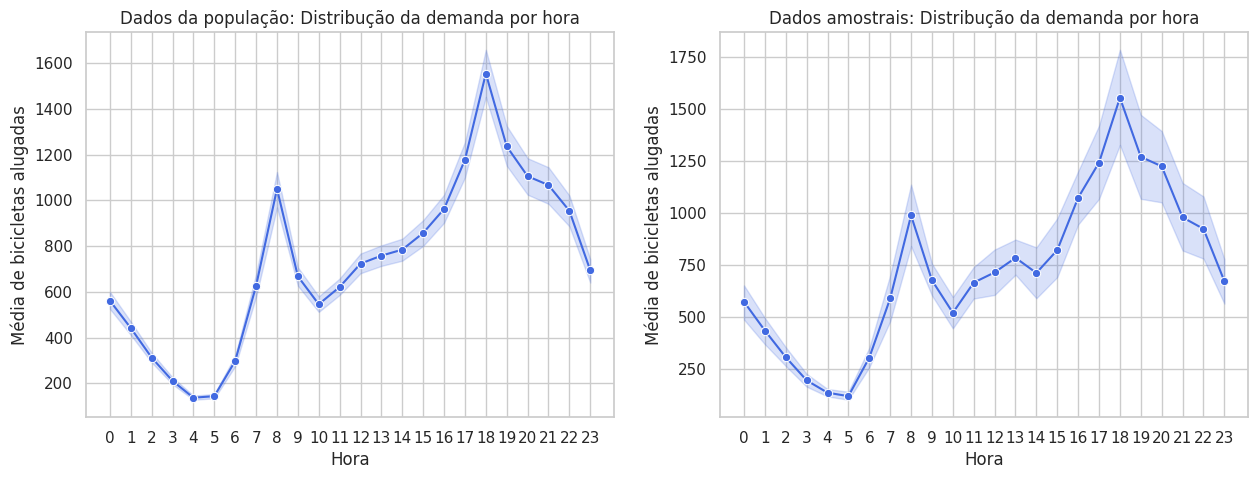

In [ ]:
# Comparando amostra com os dados da população pelo gráfico

fig, axes = plt.subplots(1,2, figsize=(15,5))

sns.lineplot(data = df_func, x='hour', y='rented_bike_count', marker='o', color='royalblue', ax=axes[0])
axes[0].set_title('Dados da população: Distribução da demanda por hora')
axes[0].set_xlabel('Hora')
axes[0].set_ylabel('Média de bicicletas alugadas')
axes[0].set_xticks(range(0, 24))

sns.lineplot(data = amostra, x='hour', y='rented_bike_count', marker='o', color='royalblue', ax=axes[1])
axes[1].set_title('Dados amostrais: Distribução da demanda por hora')
axes[1].set_xlabel('Hora')
axes[1].set_ylabel('Média de bicicletas alugadas')
axes[1].set_xticks(range(0, 24))

plt.show()

In [26]:
# Calculando a proporcao percentual de cada estacao

prop_pop = df_func['seasons'].value_counts(normalize=True) * 100
prop_amostra = amostra['seasons'].value_counts(normalize=True) * 100

comparativo_estratos = pd.DataFrame({
    'População (%)': prop_pop,
    'Amostra (%)': prop_amostra,
    'Diferença (%)': (prop_pop - prop_amostra).abs()
})

print("--- Comparação Proporcional das Estações ---")
display(comparativo_estratos.round(2))

# Comparacao rapida de media e mediana

print("\n--- Comparação das Métricas Centrais ---")
print(f"Média População: {df_func['rented_bike_count'].mean():.2f} | Média Amostra: {amostra['rented_bike_count'].mean():.2f}")
print(f"Mediana População: {df_func['rented_bike_count'].median():.2f} | Mediana Amostra: {amostra['rented_bike_count'].median():.2f}")

--- Comparação Proporcional das Estações ---


,População (%),Amostra (%),Diferença (%)
seasons,,,
Autumn,22.88,22.86,0.02
Spring,25.52,25.52,0.00
Summer,26.08,26.11,0.02
Winter,25.52,25.52,0.00



--- Comparação das Métricas Centrais ---
Média População: 729.16 | Média Amostra: 727.52
Mediana População: 542.00 | Mediana Amostra: 517.00


### Conclusão da etapa 3

Logo após importar as bibliotecas necessárias e carregar o CSV tratado eu separei os registros com dias funcionais para trabalhar com eles. <p>

Depois foi a hora de criar a amostra, para isso optei pelo método de amostragem estratificada selecionando então proporcionalmente 20% de cada estação do ano. E porque estratificada pela estação do ano? Porque na etapa anterior foi constatado que a temperatura é a variável que mais contém correlação com o número de bikes alugadas.<p>

E para comprovar que a amostra representa adequadamente a população, eu criei dois gráficos de linha um do lado do outro trazendo a quantidade de bikes alugadas durante as horas do dia onde um recebe os dados da população e o outro da amostra, que demostraram possuir a mesma tendência (desenho). Também para reforçar que a amostra representa adequadamente a população criei uma tabela mostrando que as porcentagens de cada estação do ano dentro da população e da amostra estão praticamente iguais, comprovando então que essa amostra não favorece determinado grupo e que está representando bem a população.